# Folder overview

Browse the files next to this notebook. Text and JSON files are shown in full, NumPy arrays are summarized and plotted, and images are embedded below. Python files are displayed as text only; they are never executed. Re-run the cells after adding or changing files to refresh the overview.

In [11]:
from pathlib import Path
import json
import numpy as np
from IPython.display import Code, Image, Markdown, display

ROOT = Path.cwd().resolve()
NOTEBOOK_NAME = "folder_overview.ipynb"
IGNORED_DIRS = {"__pycache__", ".git"}
files = sorted(
    path for path in ROOT.rglob("*")
    if path.is_file()
    and path.name != NOTEBOOK_NAME
    and not any(part in IGNORED_DIRS for part in path.relative_to(ROOT).parts)
)

def format_size(size):
    for unit in ("B", "KiB", "MiB", "GiB"):
        if size < 1024 or unit == "GiB":
            return f"{size:.1f} {unit}" if unit != "B" else f"{size} B"
        size /= 1024

display(Markdown(f"**Folder:** `{ROOT}`  \n**Files found:** {len(files)}"), width=600)

**Folder:** `/home/jacquemier/Working_dir/LSST/clgpry/20261127_111545`  
**Files found:** 10

In [12]:
print(f"{'Path':<48} {'Type':<16} {'Size':>10}")
print("-" * 78)
for path in files:
    suffix = path.suffix.lower()
    kind = {
        ".json": "JSON",
        ".npy": "NumPy array",
        ".png": "PNG image",
        ".jpg": "JPEG image",
        ".jpeg": "JPEG image",
        ".py": "Python source",
        ".ini": "INI config",
        ".txt": "Text",
    }.get(suffix, "File")
    print(f"{str(path.relative_to(ROOT)):<48} {kind:<16} {format_size(path.stat().st_size):>10}")

Path                                             Type                   Size
------------------------------------------------------------------------------
.ipynb_checkpoints/folder_overview-checkpoint.ipynb File                6.4 KiB
benchmark_info.json                              JSON                2.4 KiB
images/surrogate_corner.png                      PNG image          70.7 KiB
images/timing.png                                PNG image          30.3 KiB
images/trace.png                                 PNG image         497.8 KiB
job_info.txt                                     Text                   19 B
likelihood_file.py                               Python source       3.7 KiB
loglike_values.npy                               NumPy array         1.1 KiB
priors_file.ini                                  INI config            553 B
sampler_file.ini                                 INI config          1.5 KiB


In [36]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".gif", ".bmp", ".webp", ".tif", ".tiff"}
for path in files:
    suffix = path.suffix.lower()
    if suffix in IMAGE_EXTENSIONS or suffix == ".npy":
        continue
    relative = path.relative_to(ROOT)
    display(Markdown(f"## `{relative}`"))
    try:
        if suffix == ".json":
            content = json.dumps(json.loads(path.read_text(encoding="utf-8")), indent=2, ensure_ascii=False)
            display(Code(content, language="json"))
        else:
            content = path.read_text(encoding="utf-8")
            language = {".ipynb": "python", ".py": "python", ".ini": "ini", ".toml": "toml", ".yaml": "yaml", ".yml": "yaml"}.get(suffix, "text")
            if language != "python" and language is not None:
                display(Code(content, language=language))
    except (UnicodeDecodeError, json.JSONDecodeError) as error:
        print(f"Could not render as text: {type(error).__name__}: {error}")

{
  "timestamp_end": "2026-11-27T11:24:28",
  "status": "success",
  "run_wall_time_s": 522.4476197399199,
  "arguments": {
    "priors_path": "./data/priors_file.ini",
    "std_path": "/sps/lsst/users/jacquem/miniforge3/envs/firecrown_clp/cosmosis-standard-library",
    "data_sacc_path": "./data/clusters_sacc_file_cov.sacc",
    "sampler_ini": "data/sampler_file.ini",
    "checkpoint": "output/intro",
    "likelihood_source": "./data/likelihood_file.py",
    "test_only": false
  },
  "command_line": [
    "/sps/lsst/users/jacquem/miniforge3/envs/firecrown_clp/bin/clgpry-run",
    "--priors-path",
    "./data/priors_file.ini",
    "--std-path",
    "/sps/lsst/users/jacquem/miniforge3/envs/firecrown_clp/cosmosis-standard-library",
    "--likelihood-source",
    "./data/likelihood_file.py",
    "--data_sacc_path",
    "./data/clusters_sacc_file_cov.sacc",
    "--sampler-ini",
    "data/sampler_file.ini"
  ],
  "priors_file": "priors_file.ini",
  "priors_content": "[cosmological_parameters]\nomega_c = 0.1 0.22 0.5\nsigma_8 = 0.5 0.8 1.1\nomega_b = 0.0448\nh0 = 0.71\nn_s = 0.963\nomega_k = 0.0\nw = -1.0\nwa = 0.0\ntau = 0.08\n[firecrown_number_counts]\nmass_distribution_mu0 = 3.3439\nmass_distribution_mu1 = 0.958236982\nmass_distribution_mu2 = -0.0192802\nmass_distribution_sigma0 = 0.562317194\nmass_distribution_sigma1 = 0.04552506\nmass_distribution_sigma2 = -0.0445\ncompleteness_a_n = 1.1321\ncompleteness_b_n = 0.7751\ncompleteness_a_logm_piv = 13.31\ncompleteness_b_logm_piv = 0.2025\ncluster_theory_cluster_concentration = 3.8\n",
  "mpi_processes": 3,
  "loglike_calls_success": 125,
  "loglike_calls_error": 0,
  "host": {
    "hostname": "ccwpslurm0017",
    "platform": "Linux-5.14.0-687.65.1.el9_8.x86_64-x86_64-with-glibc2.34",
    "python": "3.13.16 | packaged by conda-forge | (main, Oct  7 2026, 00:29:52) [GCC 15.3.0]",
    "cpu_model": "AMD EPYC 9334 32-Core Processor",
    "cpu_count_logical": 64,
    "cpu_affinity": 3,
    "total_memory_kb": 1320259188,
    "load_average": [
      44.92,
      38.56,
      31.36
    ],
    "env": {
      "OMP_NUM_THREADS": "1",
      "MKL_NUM_THREADS": "1",
      "OPENBLAS_NUM_THREADS": "1",
      "SLURM_JOB_ID": "64963863",
      "SLURM_CPUS_PER_TASK": "1",
      "SLURM_NTASKS": "3"
    }
  },
  "packages": {
    "gpry": "4.1",
    "numpy": "2.3.5",
    "camb": "1.6.1",
    "firecrown": "1.16.1.dev99",
    "cosmosis": "3.25.2",
    "mpi4py": "4.1.2"
  }
}

job slurm-64963863

[cosmological_parameters]
omega_c = 0.1 0.22 0.5
sigma_8 = 0.5 0.8 1.1
omega_b = 0.0448
h0 = 0.71
n_s = 0.963
omega_k = 0.0
w = -1.0
wa = 0.0
tau = 0.08
[firecrown_number_counts]
mass_distribution_mu0 = 3.3439
mass_distribution_mu1 = 0.958236982
mass_distribution_mu2 = -0.0192802
mass_distribution_sigma0 = 0.562317194
mass_distribution_sigma1 = 0.04552506
mass_distribution_sigma2 = -0.0445
completeness_a_n = 1.1321
completeness_b_n = 0.7751
completeness_a_logm_piv = 13.31
completeness_b_logm_piv = 0.2025
cluster_theory_cluster_concentration = 3.8

[runtime]
sampler = emcee
root = /sps/lsst/users/jacquem/CLPipe/tutorials
resume = F

[default]
fatal_errors = F

[output]
filename = output_rp/number_counts_samples.txt
format = text
verbosity = 0

[pipeline]
modules = consistency camb firecrown_likelihood
values = priors_file.ini
likelihoods = firecrown
quiet = F
debug = F
timing = T

[consistency]
file = ${CSL_DIR}/utility/consistency/consistency_interface.py

[camb]
file = ${CSL_DIR}/boltzmann/camb/camb_interface.py

mode = all
lmax = 2500
feedback = 0
zmin = 0.0
zmax = 10.0
nz = 100
kmin = 1e-4
kmax = 50.0
nk = 1000

[firecrown_likelihood]
;; Fix this to use an environment variable to find the files.
;; Set FIRECROWN_DIR to the base of the firecrown installation (or build, if you haven't installed it)
file = /sps/lsst/groups/clusters/cl_pipeline_project/conda_envs/firecrown_developer_clp/lib/python3.13/site-packages/firecrown/connector/cosmosis/likelihood.py
likelihood_source = likelihood_file.py
sampling_parameters_sections = firecrown_number_counts
use_cluster_counts = TRUE
use_mean_deltasigma = TRUE
use_mean_reduced_shear = FALSE
use_mean_log_mass = FALSE

[test]
fatal_errors = T
save_dir = output_counts_mean_mass

[metropolis]
samples = 1000
nsteps = 1

[emcee]
walkers = 100
samples = 20000
nsteps = 20
[polychord]
live_points = 500
num_repeats = 30
tolerance = 0.05
feedback = 1

[grpy]
n_initial = 90,
max_initial = 5000,
max_total = 200000

ValueError: The total number of evaluations 'max_total=20000' needs to be larger than or equal to the maximum number of initial evaluations 'max_initial=60000'.

## NumPy array: `loglike_values.npy`

Shape: (125,)
Dimensions: 1
Dtype: float64
Elements: 125
Finite values: 125
Min: -17329.709821151086
Max: -120.30544822826838
Mean: -1620.0718777783059
Std dev: 2789.9572468083684


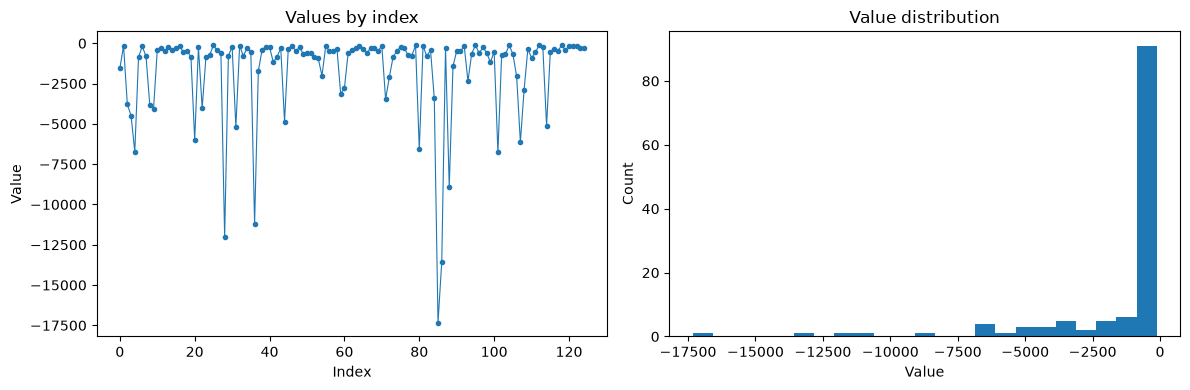

In [14]:
array_files = [path for path in files if path.suffix.lower() == ".npy"]
for path in array_files:
    display(Markdown(f"## NumPy array: `{path.relative_to(ROOT)}`"))
    try:
        array = np.load(path, allow_pickle=False)
        print(f"Shape: {array.shape}\nDimensions: {array.ndim}\nDtype: {array.dtype}\nElements: {array.size}")
        if np.issubdtype(array.dtype, np.number):
            values = array[np.isfinite(array)] if np.issubdtype(array.dtype, np.inexact) else array.ravel()
            print(f"Finite values: {values.size}\nMin: {values.min() if values.size else 'n/a'}\nMax: {values.max() if values.size else 'n/a'}\nMean: {values.mean() if values.size else 'n/a'}\nStd dev: {values.std() if values.size else 'n/a'}")
        #print("\nAll stored values:")
        #print(np.array2string(array, threshold=array.size + 1, max_line_width=120))
        if array.size and np.issubdtype(array.dtype, np.number):
            import matplotlib.pyplot as plt
            values = array.ravel()
            figure, axes = plt.subplots(1, 2, figsize=(12, 4))
            _=axes[0].plot(np.arange(values.size), values, marker=".", linewidth=0.8)
            axes[0].set(title="Values by index", xlabel="Index", ylabel="Value")
            _=axes[1].hist(values, bins="auto")
            axes[1].set(title="Value distribution", xlabel="Value", ylabel="Count")
            figure.tight_layout()
            plt.show()
    except (OSError, ValueError) as error:
        print(f"Could not load array: {type(error).__name__}: {error}")

## Image: `images/surrogate_corner.png`

Format: PNG; dimensions: 800 × 800; mode: RGBA


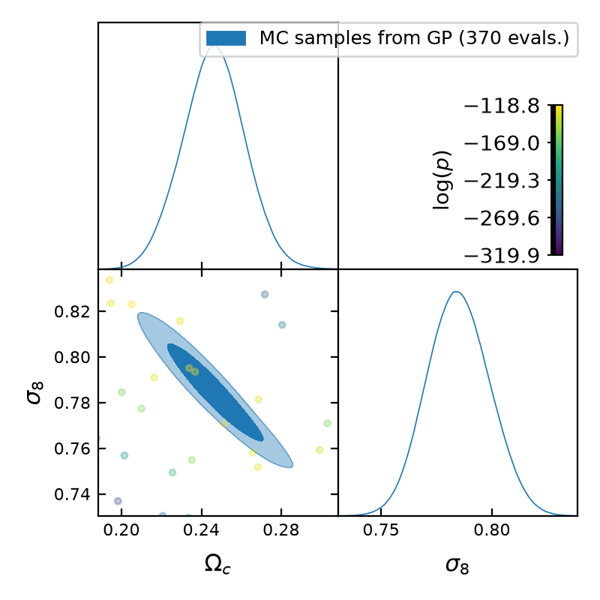

## Image: `images/timing.png`

Format: PNG; dimensions: 640 × 480; mode: RGBA


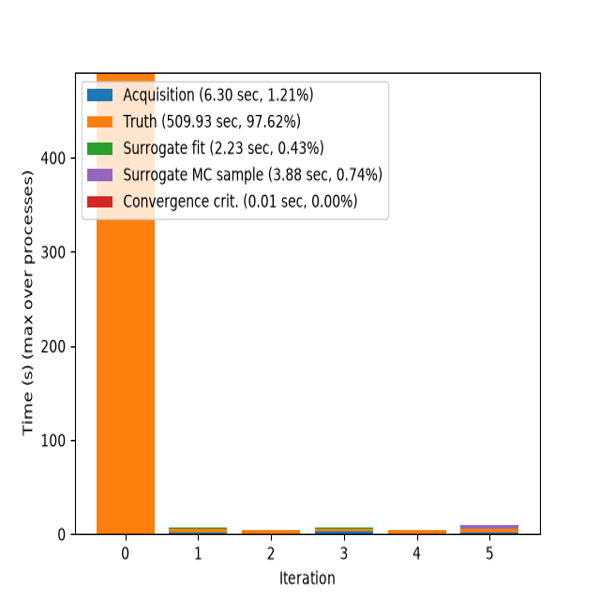

## Image: `images/trace.png`

Format: PNG; dimensions: 1600 × 2400; mode: RGBA


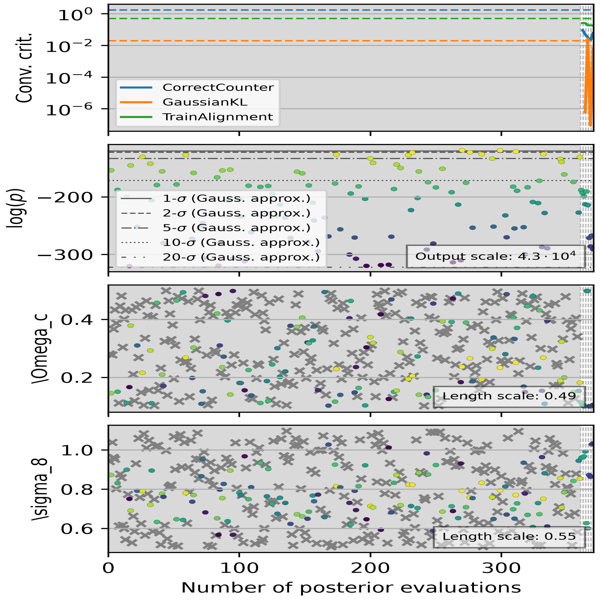

In [26]:
from PIL import Image as PILImage

scale = .3
#.resize(( int(image.width * scale), int(image.height * scale))
image_files = [path for path in files if path.suffix.lower() in IMAGE_EXTENSIONS]
for path in image_files:
    display(Markdown(f"## Image: `{path.relative_to(ROOT)}`"))
    try:
        with PILImage.open(path) as image:
            print(f"Format: {image.format}; dimensions: {image.width} × {image.height}; mode: {image.mode}")
        #image = Image(filename=str(path))        
            display(image.resize(( 600,600)))
    except (OSError, ValueError) as error:
        print(f"Could not display image: {type(error).__name__}: {error}")